In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import matplotlib
matplotlib.rcParams['figure.figsize'] = (12, 8)

import warnings
warnings.filterwarnings('ignore')

# k Nearest Neighbors (kNN)
Метод k ближайших соседей рассчитывает расстояния от нового объекта до всех объектов выборки и, отбирая k ближайших, предсказывает целевую переменную с помощью голосования (в случае классификации) или усреднения (в случае регрессии). \
При этом этот метод можно по-разному настраивать, например можно изменить способ подсчета расстояний или способ взвешивания соседей по расстоянию. \
Для начала скачаем датасет и визуализируем данные.

In [2]:
circ = pd.read_csv('concertriccir2.csv')
circ.head()

,X,Y,class
0,0.70,-0.247,0.0
1,-3.95,2.740,1.0
2,0.15,-2.160,1.0
3,-1.67,-0.942,1.0
4,2.56,-1.850,1.0


<Axes: xlabel='X', ylabel='Y'>

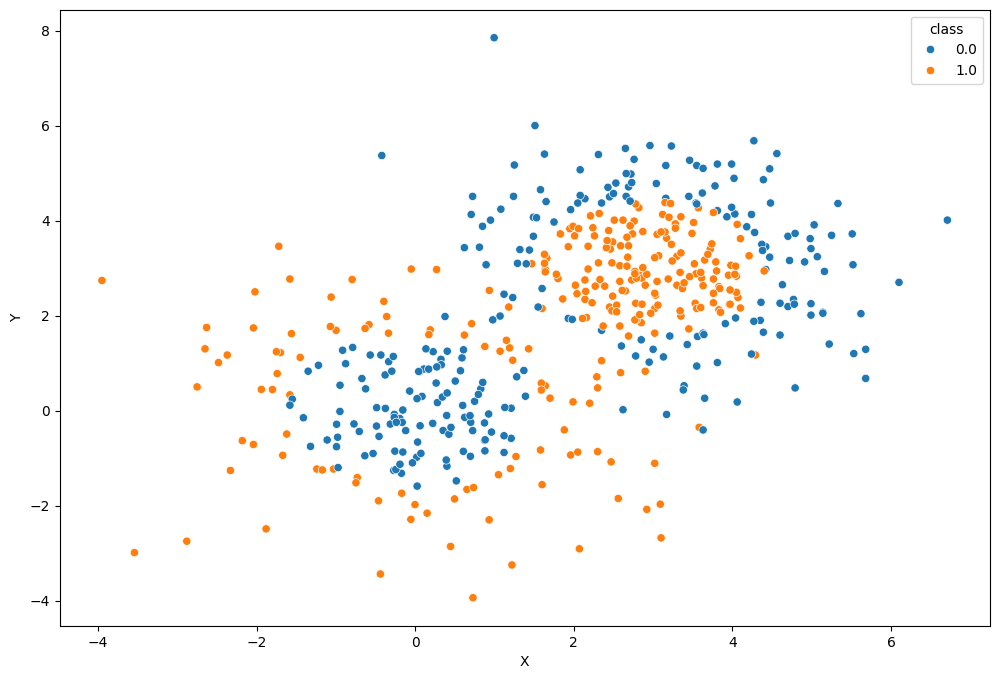

In [3]:
sns.scatterplot(data=circ, x='X', y='Y', hue='class')

**Задание 1.** Обучите логистическую регрессию на данных и нарисуйте разделяющую гиперплоскость (прямую) на рисунке с данными. Как линейный классификатор справился с задачей? Сделайте вывод исходя из геометрии данных и линии разделения. Какой accuracy выйдет на всей выборке (без валидации)?

In [4]:
X = circ.drop('class', axis=1)
y = circ['class']

In [7]:
from sklearn.linear_model import LogisticRegression

### Your code is here

model = LogisticRegression()
model.fit(X, y)

accuracy = model.score(X, y)
print(f"Accuracy: {accuracy:.4f}")



Accuracy: 0.4240


In [25]:
circ[['X']].min()

X   -3.95
dtype: float64

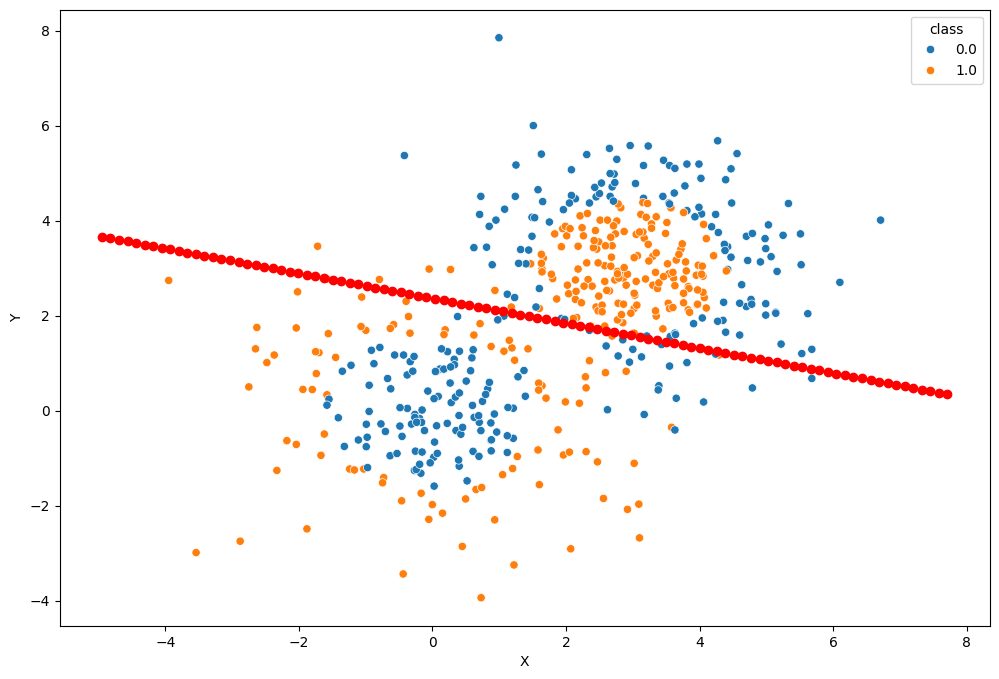

In [26]:
sns.scatterplot(data=circ, x='X', y='Y', hue='class')

x1_values = np.linspace(circ[['X']].min() - 1, circ[['X']].max() + 1, 100)
# Рассчитываем соответствующие значения по оси Y
x2_values = -(model.coef_[0][0] * x1_values + model.intercept_[0]) / model.coef_[0][1]

plt.plot(x1_values, x2_values, 'o', color='red')


**Задание 2.** Разделите обучающую выборку и обучите 6 моделей kNN с различным числом соседей из `all_k`, сохраните обученные классификаторы в список. \
Выведите accuracy на тренировочной и тестовой выборке для каждой модели. Каково оптимальное число соседей с точки зрения accuracy?

In [29]:
X = circ[['X', 'Y']].values
y = circ['class'].values.astype('int')

In [30]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, 
                                                    shuffle=True, random_state=2022)

In [33]:
from sklearn.neighbors import KNeighborsClassifier
all_k = [1, 3, 10, 30, 40, 60]

### Your code is here
for k in all_k:
    knn=KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train, y_train)
    accuracy_test = knn.score(X_test, y_test)
    accuracy_train = knn.score(X_train, y_train)
    print(f"Test Accuracy for k={k}: {accuracy_test:.4f}, Train Accuracy for k={k}: {accuracy_train:.4f}")


Test Accuracy for k=1: 0.8900, Train Accuracy for k=1: 1.0000
Test Accuracy for k=3: 0.8700, Train Accuracy for k=3: 0.9475
Test Accuracy for k=10: 0.8500, Train Accuracy for k=10: 0.9150
Test Accuracy for k=30: 0.7400, Train Accuracy for k=30: 0.8525
Test Accuracy for k=40: 0.7500, Train Accuracy for k=40: 0.8000
Test Accuracy for k=60: 0.7300, Train Accuracy for k=60: 0.6925


**Задание 3.** (бонусное) Скачайте библиотку [mlxtend](http://rasbt.github.io/mlxtend/#examples) для визуализации решающих поверхностей. 
В документации можно ознакомиться с [примерами](http://rasbt.github.io/mlxtend/user_guide/plotting/plot_decision_regions/) изображения решающих поверхностей для различных моделей. \
Построим несколько таких графиков для шести обученных нами kNN.

1. Подберите параметры `gridspec.GridSpec()` и `itertools.product()` для нашего числа классификаторов. 
2. Удобно перед визулизацией сохранить обученные классификаторы в список `all_clfs`.
3. Проявите терпение! Отрисовка решающих поверхностей может занимать пару минут.

In [ ]:
import mlxtend
from mlxtend.plotting import plot_decision_regions
import matplotlib.gridspec as gridspec
import itertools

In [ ]:
### Your code is here




1. Как меняется решающая поверхность с ростом числа соседей?
2. Какое оптимальное число соседей с точки зрения устройства данных и геометрии решающих поверхностей? Поясните свой ответ, опираясь на полученные графики.
3. Лучше ли справляется kNN по сравнению с логистической регрессией?

**Задание 4.** Скачайте уже известный вам датасет [SigmaCabs](https://www.kaggle.com/datasets/arashnic/taxi-pricing-with-mobility-analytics). Обучите классификатор kNN на отнормированных и не отнормированных данных, подобрав лучшие гиперпараметры среди $k \in [1, 5, 10]$. Замерьте качество на тестовой выборке. \
Почему нормирование данных помогает улучшить качество?

In [34]:
df = pd.read_csv('processed_sigma_cabs.csv')
df.head()

,Trip_Distance,Customer_Since_Months,Life_Style_Index,Customer_Rating,Cancellation_Last_1Month,Var1,Var2,Var3,Surge_Pricing_Type,Type_of_Cab_B,...,Destination_Type_F,Destination_Type_G,Destination_Type_H,Destination_Type_I,Destination_Type_J,Destination_Type_K,Destination_Type_L,Destination_Type_M,Destination_Type_N,Gender_Male
0,6.77,1.0,2.42769,3.90500,0,40.0,46,60,2,1,...,0,0,0,0,0,0,0,0,0,0
1,29.47,10.0,2.78245,3.45000,0,38.0,56,78,2,1,...,0,0,0,0,0,0,0,0,0,1
2,41.58,10.0,2.79805,3.50125,2,61.0,56,77,2,1,...,0,0,0,0,0,0,0,0,0,1
3,61.56,10.0,2.79805,3.45375,0,61.0,52,74,3,0,...,0,0,0,0,0,0,0,0,0,1
4,54.95,10.0,3.03453,3.40250,4,51.0,49,102,2,0,...,0,0,0,0,0,0,0,0,0,1


In [35]:
X = df.drop('Surge_Pricing_Type', axis=1)
y = df['Surge_Pricing_Type']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, 
                                                    shuffle=True, random_state=2022)

In [36]:
### Your code is here
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV

pipe = Pipeline([('scaler', StandardScaler()),
                 ('knn', KNeighborsClassifier())]
)
param_grid = {
    'knn__n_neighbors': [1, 5, 10]
}

grid_search_knn = GridSearchCV(
    pipe,
    param_grid,
    scoring='accuracy',
    cv=5,
    n_jobs=-1,
    error_score='raise'
)

grid_search_knn.fit(X_train, y_train)


print(f"Best score: {grid_search_knn.best_score_:.4f}")
print(f"Best parameters: {grid_search_knn.best_params_}")

### Your code is here





Best score: 0.6590
Best parameters: {'knn__n_neighbors': 10}


In [37]:
grid_search_knn.score(X_test, y_test)

0.6607678578209851

**Задание 5.** Обучите классификатор kNN на отнормированных данных с помощью метрики Минковского. 
$$
\rho(x, z) = \bigg(\sum_i |x_i - z_i|^p\bigg) ^{1/p}
$$

Значение параметра `p` возьмите равным единице. Замерьте качество на тестовой выборке и сравните с предыдущим заданием, где `p = 2`.

In [38]:
### Your code is here

pipe_knn = Pipeline([('scaler', StandardScaler()),
                 ('knn', KNeighborsClassifier(n_neighbors=10,p=1))]
)
pipe_knn.fit(X_train, y_train)


print(f"Best score: {pipe_knn.score(X_test, y_test):.2f}")




Best score: 0.66


**Задание 6.** Скачайте датасет [California Housing Prices](https://www.kaggle.com/datasets/camnugent/california-housing-prices), в котором мы будем предсказывать среднюю стоимость жилья. В качестве признаков будем использовать `['longitude', 'latitude']`, посмотрите на них с помощью scatterplot. \
По какой характеристике наш kNN регрессор в этом случае подбирает соседей?

1. Обучите обыкновенную линейную регрессию и замерьте RMSE на тренировочной и тестовой выборках.
2. Обучите kNN регрессор на отнормированных данных, подобрав лучшие гиперпараметры $k \in [1, 2, ..., 9]$. 
3. Обучите kNN регрессор с гауссовским ядром, взяв параметр k из предыдущего пункта и подобрав оптимальное значение ширины окна среди предложенных $h \in np.arange(0.02, 0.1, 0.01)$.

Как ширина окна влияет на веса при усреднении ответа по соседям? 

In [39]:
df = pd.read_csv('housing.csv')
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


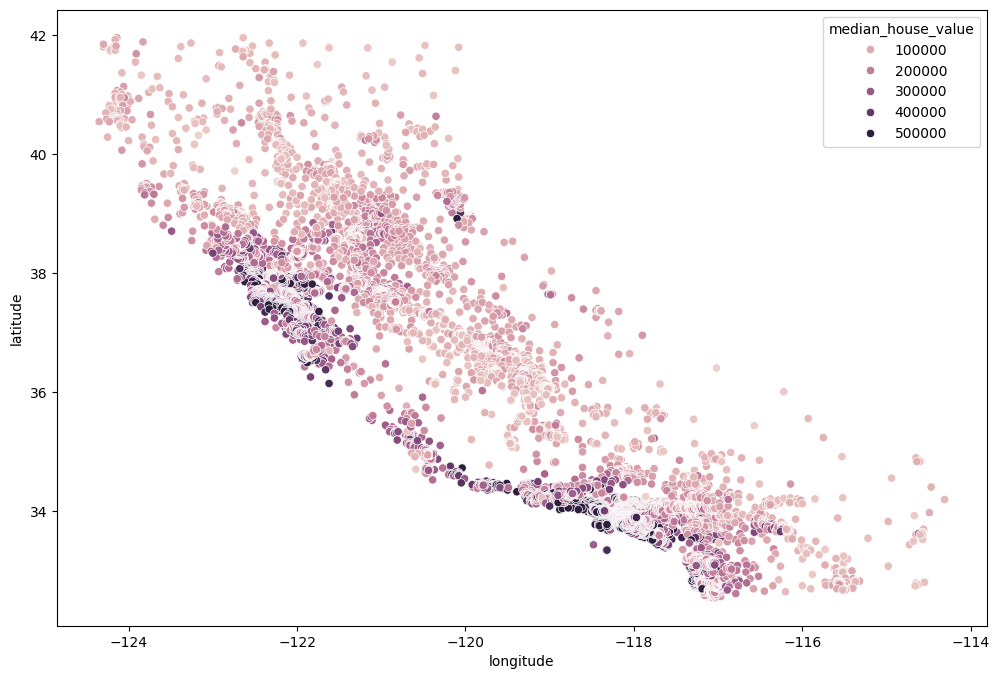

In [40]:
X = df[['longitude', 'latitude']]
y = df['median_house_value']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, 
                                                    shuffle=True, random_state=2022)
sns.scatterplot(data=X, x='longitude', y='latitude', hue=y);

In [41]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

model_ln = LinearRegression()   
model_ln.fit(X_train, y_train)

print(f"RMSE_train={np.sqrt(mean_squared_error(y_train, model_ln.predict(X_train)))}")
print(f"RMSE_test={np.sqrt(mean_squared_error(y_test, model_ln.predict(X_test)))}")



RMSE_train=100948.39976676
RMSE_test=98369.87709657704


In [45]:
pipe = Pipeline([('scaler', StandardScaler()),
                 ('knn', KNeighborsClassifier())]
)
param_grid = {
    'knn__n_neighbors': range(1,10)
}

grid_search_knn = GridSearchCV(
    pipe,
    param_grid,
    scoring='accuracy',
    cv=5,
    n_jobs=-1,
    error_score='raise'
)

grid_search_knn.fit(X_train, y_train)


print(f"Best score: {grid_search_knn.best_score_:.4f}")
print(f"Best parameters: {grid_search_knn.best_params_}")

Best score: 0.0383
Best parameters: {'knn__n_neighbors': 9}


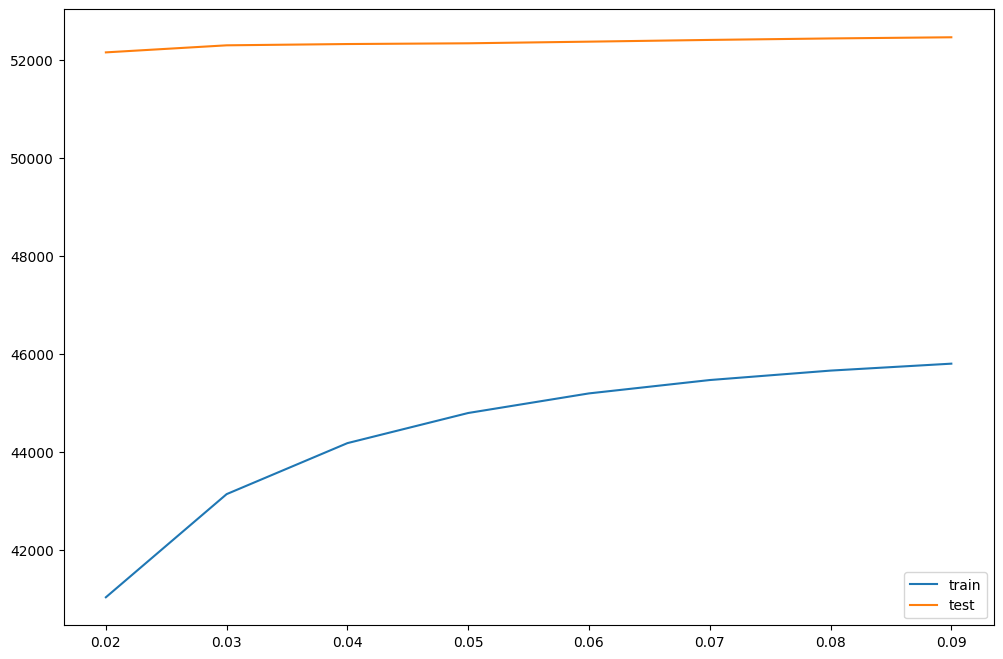

In [48]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neighbors import KernelDensity
rmse_test = []
rmse_train = []
def kernel(distances, h):
        const = 1 / (np.sqrt(2 * np.pi))
        power = (-1/2) * ((distances)**2) / h**2
        return const * np.exp(power)

for h in np.arange(0.02, 0.1, 0.01):
    knn = KNeighborsRegressor(n_neighbors=9, weights=lambda dists: kernel(dists, h=h))
    knn.fit(X_train, y_train)
    preds_test = knn.predict(X_test)
    rmse_test.append(np.sqrt(mean_squared_error(y_test, preds_test)))
    rmse_train.append(np.sqrt(mean_squared_error(y_train, knn.predict(X_train))))

plt.plot(np.arange(0.02, 0.1, 0.01), rmse_train, label='train')
plt.plot(np.arange(0.02, 0.1, 0.01), rmse_test, label='test')
plt.legend()
plt.show()
    